# Analyse des ventes et de l’expérience client chez Olist

**Projet d’analyse de données — Python**

## Contexte et objectif
Olist est une plateforme brésilienne de commerce en ligne. Ce projet exploite les commandes réalisées entre 2016 et 2018 pour repérer les évolutions des ventes, les catégories importantes et les irritants liés à la livraison et à la satisfaction. Les données sont anonymisées et proviennent du jeu public Kaggle.

### Questions métier
1. Comment le nombre de commandes et le chiffre d’affaires évoluent-ils par mois ?
2. Quelles catégories de produits contribuent le plus au chiffre d’affaires ?
3. Les retards de livraison sont-ils associés à des notes clients plus faibles ?
4. Quels États concentrent les commandes et lesquels connaissent les délais de livraison les plus longs ?
5. Quels moyens de paiement sont utilisés et quel est leur montant moyen par commande ?

> Le chiffre d’affaires est estimé par la somme du prix des articles (hors frais de livraison et remboursements éventuels). Le jeu est historique et ne permet pas de conclure à une relation causale.

### Source et licence
Source : [Brazilian E-Commerce Public Dataset by Olist — Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce). Licence indiquée par Kaggle : CC BY-NC-SA 4.0. Données historiques couvrant 2016–2018.

In [1]:
from pathlib import Path
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 50)
plt.style.use('seaborn-v0_8-whitegrid')

# DATA_DIR peut pointer vers le dossier contenant les CSV.
candidates = [
    Path(os.environ['DATA_DIR']) if os.environ.get('DATA_DIR') else None,
    Path('../data'), Path('data'), Path('../../data'),
    Path.home() / 'Downloads' / 'archive',
]
DATA_DIR = next((p.resolve() for p in candidates if p and (p / 'olist_orders_dataset.csv').exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Placez les CSV dans data/ ou définissez la variable DATA_DIR.')
print('Dossier de données :', DATA_DIR)

def load_csv(name, **kwargs):
    return pd.read_csv(DATA_DIR / name, **kwargs)


Dossier de données : /Users/mel/Downloads/archive


## 1. Chargement et contrôle initial
On charge uniquement les tables nécessaires aux questions. Les identifiants sont lus comme du texte pour préserver leur format.

In [2]:
orders = load_csv('olist_orders_dataset.csv', dtype={'order_id':'string','customer_id':'string'})
items = load_csv('olist_order_items_dataset.csv', dtype={'order_id':'string','product_id':'string','seller_id':'string'})
customers = load_csv('olist_customers_dataset.csv', dtype={'customer_id':'string','customer_unique_id':'string'})
products = load_csv('olist_products_dataset.csv', dtype={'product_id':'string'})
reviews = load_csv('olist_order_reviews_dataset.csv', dtype={'order_id':'string'})
payments = load_csv('olist_order_payments_dataset.csv', dtype={'order_id':'string'})
translation = load_csv('product_category_name_translation.csv')

frames = {'orders':orders,'items':items,'customers':customers,'products':products,'reviews':reviews,'payments':payments,'translation':translation}
profile = pd.DataFrame([{'table':n,'rows':len(d),'columns':d.shape[1],'missing_cells':int(d.isna().sum().sum()),'duplicate_rows':int(d.duplicated().sum())} for n,d in frames.items()])
display(profile)


,table,rows,columns,missing_cells,duplicate_rows
0,orders,99441,8,4908,0
1,items,112650,7,0,0
2,customers,99441,5,0,0
3,products,32951,9,2448,0
4,reviews,99224,7,145903,0
5,payments,103886,5,0,0
6,translation,71,2,0,0


## 2. Nettoyage documenté
Les lignes sans date de livraison restent utiles pour l’analyse des ventes, mais sont exclues du calcul des délais. Les commandes annulées ou indisponibles sont exclues des indicateurs de ventes livrées. Les champs texte d’avis manquants ne sont pas nécessaires aux questions retenues. On supprime les doublons exacts de géolocalisation si cette table est utilisée, mais elle n’est pas requise ici.

In [3]:
# Conversion explicite des dates; valeurs non interprétables deviennent NaT.
date_cols = ['order_purchase_timestamp','order_approved_at','order_delivered_carrier_date','order_delivered_customer_date','order_estimated_delivery_date']
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')

# Quantifier les anomalies avant toute exclusion.
quality = pd.DataFrame({
    'missing_count': orders.isna().sum(),
    'missing_pct': (orders.isna().mean()*100).round(2),
})
display(quality[quality.missing_count.gt(0)].sort_values('missing_count', ascending=False))
print('Doublons exacts commandes :', orders.duplicated().sum())
print('Identifiants commande dupliqués :', orders.order_id.duplicated().sum())
print('Articles à prix nul/négatif :', int((items.price <= 0).sum()))
print('Notes hors plage 1–5 :', int((~reviews.review_score.between(1,5)).sum()))

# Les données d’avis peuvent avoir plusieurs lignes par commande : on conserve
# une note moyenne par commande avant jointure afin d’éviter de multiplier les articles.
review_by_order = reviews.groupby('order_id', as_index=False).agg(review_score=('review_score','mean'))
# L’ordre de jointure respecte les granularités : articles puis commande, client, produit.
orders_items = items.merge(orders, on='order_id', how='left', validate='many_to_one')
orders_items = orders_items.merge(customers[['customer_id','customer_state','customer_unique_id']], on='customer_id', how='left', validate='many_to_one')
orders_items = orders_items.merge(products[['product_id','product_category_name']], on='product_id', how='left', validate='many_to_one')
orders_items = orders_items.merge(translation, on='product_category_name', how='left', validate='many_to_one')
print('Lignes articles avant jointures :', len(items), '| après :', len(orders_items))
print('Articles sans commande correspondante :', int(orders_items.order_status.isna().sum()))
print('Articles sans traduction de catégorie :', int(orders_items.product_category_name_english.isna().sum()))


,missing_count,missing_pct
order_delivered_customer_date,2965,2.98
order_delivered_carrier_date,1783,1.79
order_approved_at,160,0.16


Doublons exacts commandes : 0
Identifiants commande dupliqués : 0
Articles à prix nul/négatif : 0
Notes hors plage 1–5 : 0
Lignes articles avant jointures : 112650 | après : 112650
Articles sans commande correspondante : 0
Articles sans traduction de catégorie : 1627


## 3. Construction des indicateurs
L’unité de vente est la commande; l’unité de ligne pour les produits est l’article. Pour éviter le double comptage des ventes, les montants d’articles sont d’abord sommés par commande.

In [4]:
orders_items['month'] = orders_items.order_purchase_timestamp.dt.to_period('M').dt.to_timestamp()
orders_items['item_revenue'] = orders_items.price
orders_items['delay_days'] = (orders_items.order_delivered_customer_date - orders_items.order_estimated_delivery_date).dt.total_seconds() / 86400

# Une ligne par commande pour les ventes et les paiements.
order_sales = (orders_items.groupby('order_id', as_index=False)
               .agg(order_revenue=('item_revenue','sum'), month=('month','first'),
                    order_status=('order_status','first'), customer_id=('customer_id','first'),
                    customer_state=('customer_state','first'),
                    delivered=('order_delivered_customer_date','first'),
                    estimated=('order_estimated_delivery_date','first')))
order_sales['delay_days'] = (order_sales.delivered - order_sales.estimated).dt.total_seconds()/86400
completed = order_sales[order_sales.order_status.eq('delivered')].copy()
monthly = completed.groupby('month').agg(orders=('order_id','nunique'), revenue=('order_revenue','sum')).reset_index()


## 4. Évolution mensuelle des commandes et du chiffre d’affaires
**Question 1.** Les séries s’appuient sur les commandes livrées et la date d’achat. La période d’observation s’arrête en 2018; le jeu ne décrit pas la situation actuelle d’Olist.

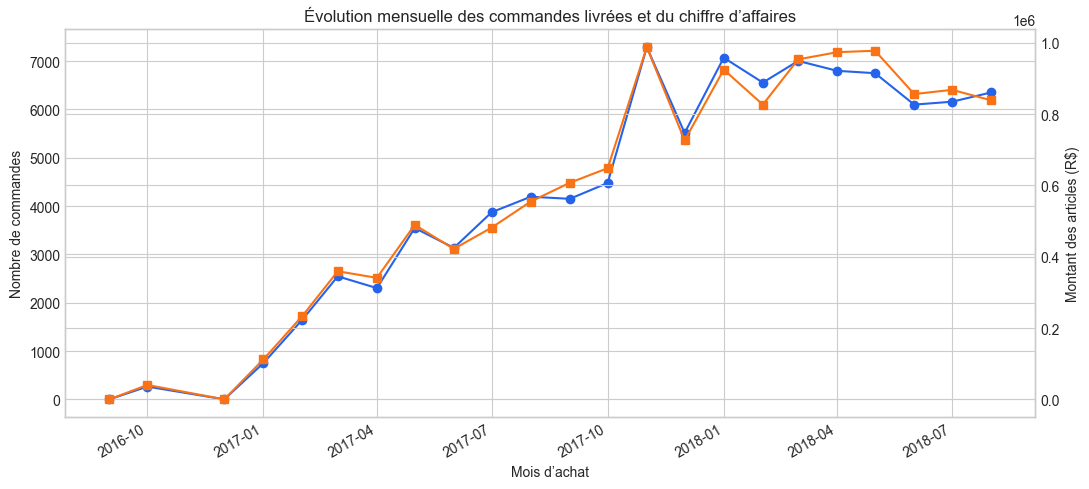

,month,orders,revenue
11,2017-09-01 00:00:00,4150,"R$ 607,400"
12,2017-10-01 00:00:00,4478,"R$ 648,248"
13,2017-11-01 00:00:00,7289,"R$ 987,765"
14,2017-12-01 00:00:00,5513,"R$ 726,033"
15,2018-01-01 00:00:00,7069,"R$ 924,645"
16,2018-02-01 00:00:00,6555,"R$ 826,437"
17,2018-03-01 00:00:00,7003,"R$ 953,356"
18,2018-04-01 00:00:00,6798,"R$ 973,534"
19,2018-05-01 00:00:00,6749,"R$ 977,545"
20,2018-06-01 00:00:00,6099,"R$ 856,078"


In [5]:
fig, ax1 = plt.subplots(figsize=(11,5))
ax1.plot(monthly.month, monthly.orders, marker='o', color='#2563eb', label='Commandes livrées')
ax1.set_ylabel('Nombre de commandes')
ax1.set_xlabel('Mois d’achat')
ax2 = ax1.twinx()
ax2.plot(monthly.month, monthly.revenue, marker='s', color='#f97316', label='Chiffre d’affaires articles')
ax2.set_ylabel('Montant des articles (R$)')
ax1.set_title('Évolution mensuelle des commandes livrées et du chiffre d’affaires')
fig.autofmt_xdate(); fig.tight_layout(); plt.show()
display(monthly.tail(12).style.format({'revenue':'R$ {:,.0f}'}))


## 5. Catégories et contribution au chiffre d’affaires
**Question 2.** Le revenu est la somme du prix des articles; on traduit les catégories en anglais lorsqu’une traduction est disponible.

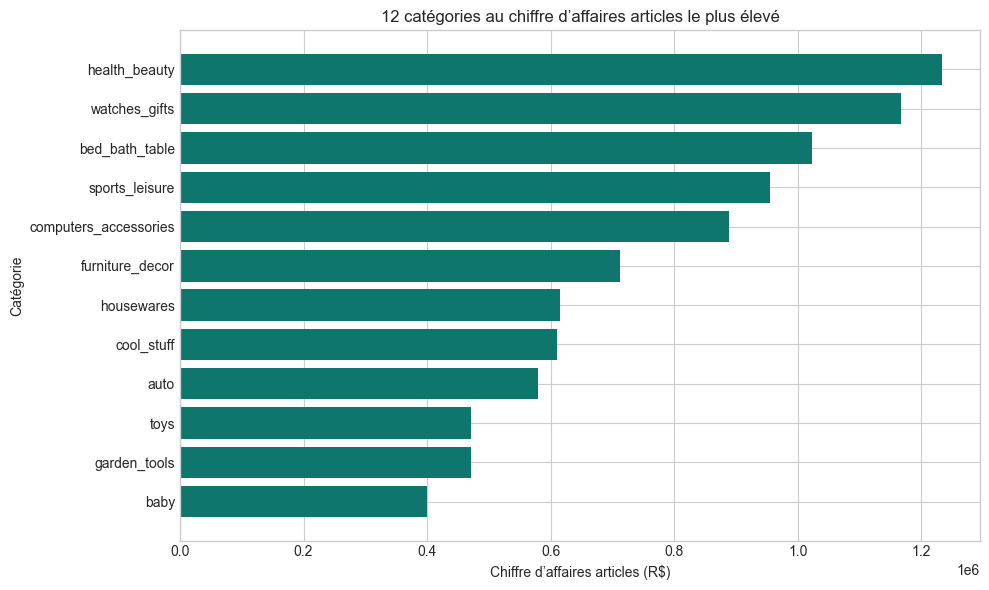

,category,revenue,items,revenue_share_pct
43,health_beauty,"R$ 1,233,132",9465,9.3%
73,watches_gifts,"R$ 1,166,177",5859,8.8%
7,bed_bath_table,"R$ 1,023,435",10953,7.7%
67,sports_leisure,"R$ 954,853",8431,7.2%
15,computers_accessories,"R$ 888,725",7644,6.7%
39,furniture_decor,"R$ 711,928",8160,5.4%
49,housewares,"R$ 615,629",6795,4.7%
20,cool_stuff,"R$ 610,204",3718,4.6%
5,auto,"R$ 578,967",4140,4.4%
71,toys,"R$ 471,286",4030,3.6%


In [6]:
category = (orders_items[orders_items.order_status.eq('delivered')]
            .assign(category=lambda d: d.product_category_name_english.fillna(d.product_category_name).fillna('unknown'))
            .groupby('category', as_index=False).agg(revenue=('price','sum'), items=('order_id','size'))
            .sort_values('revenue', ascending=False))
category['revenue_share_pct'] = category.revenue / category.revenue.sum() * 100
topcat = category.head(12).sort_values('revenue')
plt.figure(figsize=(10,6)); plt.barh(topcat.category, topcat.revenue, color='#0f766e')
plt.title('12 catégories au chiffre d’affaires articles le plus élevé')
plt.xlabel('Chiffre d’affaires articles (R$)'); plt.ylabel('Catégorie'); plt.tight_layout(); plt.show()
display(category.head(12).style.format({'revenue':'R$ {:,.0f}','revenue_share_pct':'{:.1f}%'}))


## 6. Retards de livraison et satisfaction
**Question 3.** Le retard est défini comme la date de livraison réelle moins la date estimée; une valeur positive indique une livraison après la date promise. Les commandes sans date réelle ou estimée ne contribuent pas à cette comparaison.

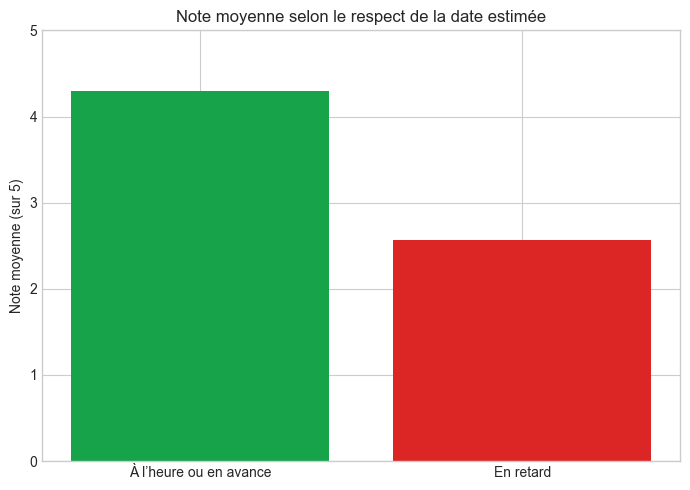

,delivery_group,orders,avg_score,median_delay
0,À l’heure ou en avance,88163,4.29,-12.32
1,En retard,7661,2.57,5.78


Taille analysée : 95824 commandes avec délai et note


In [7]:
delivery_reviews = completed[['order_id','delay_days']].merge(review_by_order, on='order_id', how='inner', validate='one_to_one').dropna(subset=['delay_days','review_score'])
delivery_reviews['delivery_group'] = np.select([delivery_reviews.delay_days > 0, delivery_reviews.delay_days <= 0], ['En retard','À l’heure ou en avance'], default='Non disponible')
summary_delivery = delivery_reviews.groupby('delivery_group').agg(orders=('order_id','nunique'), avg_score=('review_score','mean'), median_delay=('delay_days','median')).reindex(['À l’heure ou en avance','En retard']).reset_index()
plt.figure(figsize=(7,5)); plt.bar(summary_delivery.delivery_group, summary_delivery.avg_score, color=['#16a34a','#dc2626'])
plt.ylim(0,5); plt.ylabel('Note moyenne (sur 5)'); plt.title('Note moyenne selon le respect de la date estimée'); plt.tight_layout(); plt.show()
display(summary_delivery.round(2))
print('Taille analysée :', len(delivery_reviews), 'commandes avec délai et note')


## 7. Répartition géographique et délais
**Question 4.** Les effectifs sont présentés par État client. Les délais moyens sont calculés parmi les commandes livrées ayant les deux dates nécessaires.

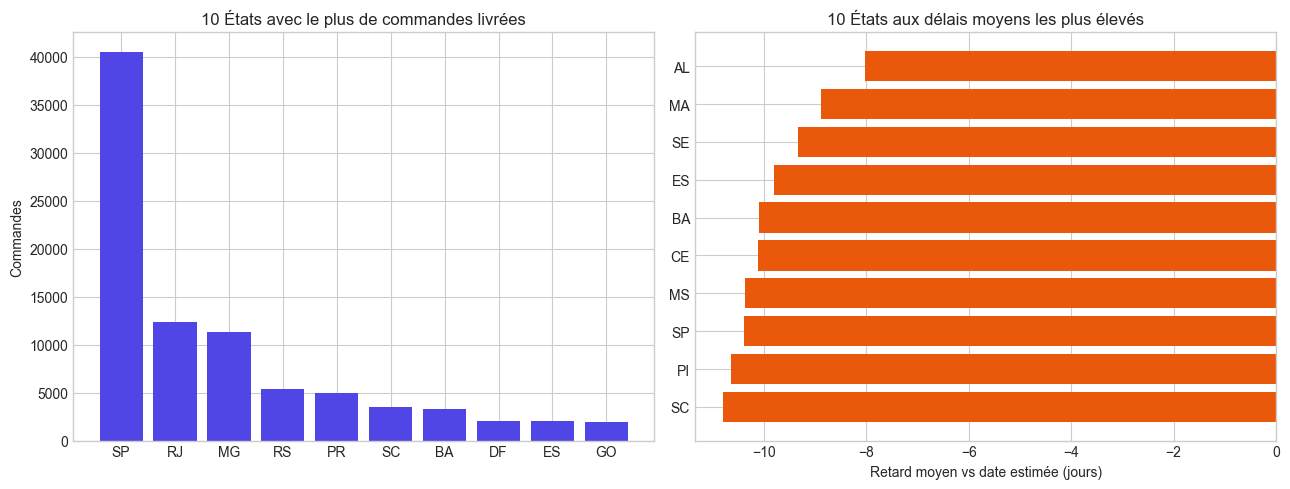

,customer_state,orders,avg_delay_days
25,SP,40501,-10.38
18,RJ,12350,-11.05
10,MG,11354,-12.54
22,RS,5345,-13.21
17,PR,4923,-12.62
23,SC,3546,-10.80
4,BA,3256,-10.10
6,DF,2080,-11.34
7,ES,1995,-9.80
8,GO,1957,-11.48


In [8]:
state = (completed.groupby('customer_state').agg(orders=('order_id','nunique'), avg_delay_days=('delay_days','mean')).reset_index().sort_values('orders', ascending=False))
fig, axes = plt.subplots(1,2,figsize=(13,5))
axes[0].bar(state.head(10).customer_state, state.head(10).orders, color='#4f46e5'); axes[0].set_title('10 États avec le plus de commandes livrées'); axes[0].set_ylabel('Commandes')
slow = state.dropna(subset=['avg_delay_days']).sort_values('avg_delay_days', ascending=False).head(10).sort_values('avg_delay_days')
axes[1].barh(slow.customer_state, slow.avg_delay_days, color='#ea580c'); axes[1].set_title('10 États aux délais moyens les plus élevés'); axes[1].set_xlabel('Retard moyen vs date estimée (jours)')
fig.tight_layout(); plt.show()
display(state.head(10).round(2))


## 8. Moyens de paiement
**Question 5.** Les paiements contiennent plusieurs lignes par commande. On agrège d’abord par type de paiement; le montant moyen est donc le montant associé à ce type, pas nécessairement la dépense totale moyenne d’un client.

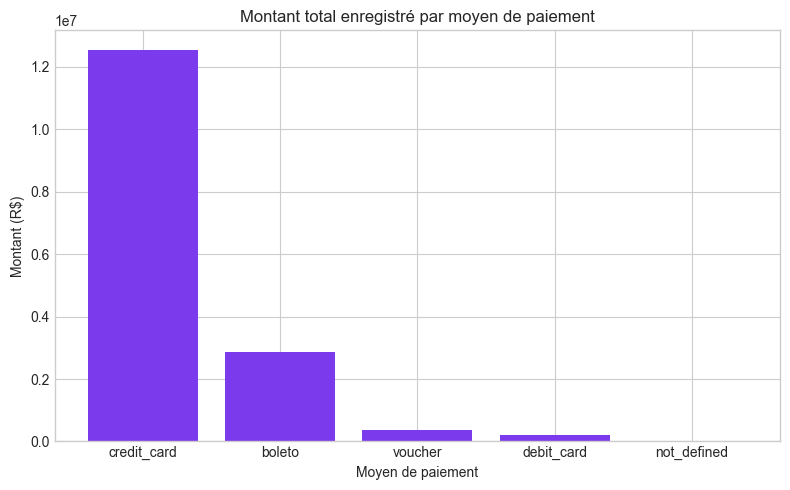

,payment_type,payment_rows,orders,total_value,avg_value
1,credit_card,76795,76505,"R$ 12,542,084",R$ 163.32
0,boleto,19784,19784,"R$ 2,869,361",R$ 145.03
4,voucher,5775,3866,"R$ 379,437",R$ 65.70
2,debit_card,1529,1528,"R$ 217,990",R$ 142.57
3,not_defined,3,3,R$ 0,R$ 0.00


In [9]:
payment = (payments.groupby('payment_type', as_index=False).agg(payment_rows=('order_id','size'), orders=('order_id','nunique'), total_value=('payment_value','sum'), avg_value=('payment_value','mean')).sort_values('total_value', ascending=False))
plt.figure(figsize=(8,5)); plt.bar(payment.payment_type, payment.total_value, color='#7c3aed')
plt.title('Montant total enregistré par moyen de paiement'); plt.ylabel('Montant (R$)'); plt.xlabel('Moyen de paiement'); plt.tight_layout(); plt.show()
display(payment.style.format({'total_value':'R$ {:,.0f}','avg_value':'R$ {:,.2f}'}))


## 9. Conclusion et limites
Compléter cette section après exécution des cellules et lecture des tableaux : répondre explicitement à chacune des cinq questions avec les chiffres observés et renvoyer aux graphiques.

### Limites à rappeler
- Les commandes datent de 2016 à 2018; elles ne décrivent pas le marché actuel.
- Les données sont observationnelles : les associations ne prouvent pas qu’un retard cause une mauvaise note.
- Le chiffre d’affaires calculé additionne les prix d’articles et exclut les frais de livraison, remboursements et coûts.
- Les lignes de commande annulées ou non livrées ne sont pas incluses dans les ventes livrées.
- Les avis peuvent manquer; l’analyse de satisfaction porte uniquement sur les commandes avec avis et dates exploitables.
- Les clients sont anonymisés et la géographie est agrégée au niveau des États.